/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Model Valid: True

Evidence: {'Xray': 1}
+------------+----------------+
| Disease    |   phi(Disease) |
+============+================+
| Disease(0) |         0.2450 |
+------------+----------------+
| Disease(1) |         0.7550 |
+------------+----------------+

Evidence: {'Xray': 1, 'Cough': 1}
+------------+----------------+
| Disease    |   phi(Disease) |
+============+================+
| Disease(0) |         0.0750 |
+------------+----------------+
| Disease(1) |         0.9250 |
+------------+----------------+

Evidence: {'Xray': 1, 'Cough': 1, 'Smoking': 1}
+------------+----------------+
| Disease    |   phi(Disease) |
+============+================+
| Disease(0) |         0.0222 |
+------------+----------------+
| Disease(1) |         0.9778 |
+------------+----------------+
Approximate Probability:
0.936


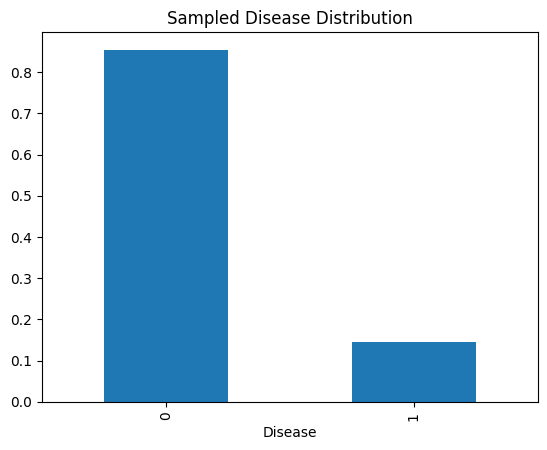

In [14]:

!pip -q install pgmpy

import numpy as np
import matplotlib.pyplot as plt

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling

model = DiscreteBayesianNetwork([
    ("Smoking", "Disease"),
    ("Pollution", "Disease"),
    ("Disease", "Cough"),
    ("Disease", "Xray")
])

model.add_cpds(
    TabularCPD("Smoking", 2, [[.7], [.3]]),

    TabularCPD("Pollution", 2, [[.6], [.4]]),

    TabularCPD(
        "Disease", 2,
        [[.99, .9, .9, .2],
         [.01, .1, .1, .8]],
        evidence=["Smoking", "Pollution"],
        evidence_card=[2, 2]
    ),

    TabularCPD(
        "Cough", 2,
        [[.8, .2], [.2, .8]],
        evidence=["Disease"],
        evidence_card=[2]
    ),

    TabularCPD(
        "Xray", 2,
        [[.95, .1], [.05, .9]],
        evidence=["Disease"],
        evidence_card=[2]
    )
)

print("Model Valid:", model.check_model())

infer = VariableElimination(model)

for evidence in [
    {"Xray": 1},
    {"Xray": 1, "Cough": 1},
    {"Xray": 1, "Cough": 1, "Smoking": 1}
]:
    print("\nEvidence:", evidence)
    print(infer.query(["Disease"], evidence=evidence))

sampler = BayesianModelSampling(model)

samples = sampler.forward_sample(
    size=10000, show_progress=False
)

subset = samples[
    (samples.Xray == 1) &
    (samples.Cough == 1)
]

print("Approximate Probability:")
print((subset.Disease == 1).mean())

samples.Disease.value_counts(
    normalize=True
).plot(kind="bar")

plt.title("Sampled Disease Distribution")
plt.show()
